# Bank Marketing Campaign Analysis

**Question:** A Portuguese bank ran phone campaigns to sell term deposits. Which customers are most likely to subscribe, and how could the bank make its calls more efficient?

**Data:** [UCI Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing) (`bank-full.csv`, 45,211 calls, 17 columns).

**Tools:** Python (pandas, matplotlib), SQL (SQLite)

**Steps:** 1) load and check the data, 2) clean it, 3) answer business questions with SQL and pandas, 4) visualize, 5) recommendations.

from google.colab import files
uploaded = files.upload()


In [7]:
import io, urllib.request, zipfile

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
inner = zipfile.ZipFile(io.BytesIO(outer.read("bank.zip")))
inner.extract("bank-full.csv")
print("Downloaded bank-full.csv")

Downloaded bank-full.csv


## 1. Load the data

In [8]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Works both locally (data/ folder) and in Google Colab (file uploaded next to the notebook)
DATA_PATH = Path("data/bank-full.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("bank-full.csv")
IMG_DIR = Path("images")
IMG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.figsize": (9, 5), "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(DATA_PATH, sep=";")
print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Check data quality

In [9]:
# Column types and missing values
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Missing values per column:
 age          0
job          0
marital      0
education    0
default   

In [10]:
# This dataset marks missing categories as the text 'unknown' instead of NaN
unknown_share = (df.select_dtypes(include=["object", "string"]) == "unknown").mean().sort_values(ascending=False)
unknown_share[unknown_share > 0].round(3)

,0
poutcome,0.817
contact,0.288
education,0.041
job,0.006


## 3. Clean and prepare

- Turn the target `y` (yes/no) into 1/0 so averages give conversion rates.
- `pdays = -1` means the customer was never contacted before, so create a clear flag for it.
- Group ages into bands that are easier to read than single ages.
- Put months in calendar order.
- Leave out `duration` (call length) from the targeting analysis: it is only known *after* the call, so it cannot be used to decide whom to call.

In [11]:
clean = df.drop_duplicates().copy()

clean["subscribed"] = (clean["y"] == "yes").astype(int)
clean["previously_contacted"] = (clean["pdays"] != -1).astype(int)

clean["age_group"] = pd.cut(
    clean["age"],
    bins=[17, 24, 34, 44, 54, 64, 120],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
)

month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
clean["month"] = pd.Categorical(clean["month"], categories=month_order, ordered=True)

clean = clean.drop(columns=["y"])
print(clean.shape)
clean.head()

(45211, 19)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,subscribed,previously_contacted,age_group
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0,0,55-64
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0,0,35-44
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0,0,25-34
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0,0,45-54
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0,0,25-34


## 4. Overall conversion rate

In [12]:
overall_rate = clean["subscribed"].mean()
print(f"Calls: {len(clean):,}")
print(f"Subscriptions: {clean['subscribed'].sum():,}")
print(f"Overall conversion rate: {overall_rate:.1%}")

Calls: 45,211
Subscriptions: 5,289
Overall conversion rate: 11.7%


## 5. Business questions with SQL

Load the cleaned table into an in-memory SQLite database and answer questions the way an analyst would with a company database.

In [13]:
conn = sqlite3.connect(":memory:")
sql_df = clean.assign(age_group=clean["age_group"].astype(str), month=clean["month"].astype(str))
sql_df.to_sql("calls", conn, index=False)

def run_sql(query):
    return pd.read_sql_query(query, conn)

In [14]:
# Q1: Which job groups convert best? (only groups with 500+ calls, to avoid tiny samples)
job_rates = run_sql("""
    SELECT job,
           COUNT(*)                         AS calls,
           SUM(subscribed)                  AS subscriptions,
           ROUND(AVG(subscribed) * 100, 1)  AS conversion_pct
    FROM calls
    WHERE job <> 'unknown'
    GROUP BY job
    HAVING COUNT(*) >= 500
    ORDER BY conversion_pct DESC
""")
job_rates

,job,calls,subscriptions,conversion_pct
0,student,938,269,28.7
1,retired,2264,516,22.8
2,unemployed,1303,202,15.5
3,management,9458,1301,13.8
4,admin.,5171,631,12.2
5,self-employed,1579,187,11.8
6,technician,7597,840,11.1
7,services,4154,369,8.9
8,housemaid,1240,109,8.8
9,entrepreneur,1487,123,8.3


In [15]:
# Q2: Does the result of a previous campaign predict this one?
prev_outcome = run_sql("""
    SELECT poutcome                         AS previous_outcome,
           COUNT(*)                         AS calls,
           ROUND(AVG(subscribed) * 100, 1)  AS conversion_pct
    FROM calls
    GROUP BY poutcome
    ORDER BY conversion_pct DESC
""")
prev_outcome

,previous_outcome,calls,conversion_pct
0,success,1511,64.7
1,other,1840,16.7
2,failure,4901,12.6
3,unknown,36959,9.2


In [16]:
# Q3: Which contact channel works better?
channel = run_sql("""
    SELECT contact,
           COUNT(*)                         AS calls,
           ROUND(AVG(subscribed) * 100, 1)  AS conversion_pct
    FROM calls
    GROUP BY contact
    ORDER BY conversion_pct DESC
""")
channel

,contact,calls,conversion_pct
0,cellular,29285,14.9
1,telephone,2906,13.4
2,unknown,13020,4.1


## 6. Deeper analysis with pandas

In [17]:
# Conversion by age group
age_rates = (
    clean.groupby("age_group", observed=True)["subscribed"]
    .agg(calls="count", conversion_rate="mean")
)
age_rates["conversion_rate"] = (age_rates["conversion_rate"] * 100).round(1)
age_rates

,calls,conversion_rate
age_group,,
18-24,809,25.6
25-34,14204,12.5
35-44,14534,9.7
45-54,9958,9.3
55-64,4896,13.1
65+,810,42.1


In [18]:
# Conversion and call volume by month
month_rates = (
    clean.groupby("month", observed=True)["subscribed"]
    .agg(calls="count", conversion_rate="mean")
)
month_rates["conversion_rate"] = (month_rates["conversion_rate"] * 100).round(1)
month_rates

,calls,conversion_rate
month,,
jan,1403,10.1
feb,2649,16.6
mar,477,52.0
apr,2932,19.7
may,13766,6.7
jun,5341,10.2
jul,6895,9.1
aug,6247,11.0
sep,579,46.5


In [19]:
# Do repeated calls in the same campaign pay off?
calls_band = pd.cut(clean["campaign"], bins=[0, 1, 2, 3, 5, 10, 100],
                    labels=["1", "2", "3", "4-5", "6-10", "11+"])
call_rates = (
    clean.groupby(calls_band, observed=True)["subscribed"]
    .agg(customers="count", conversion_rate="mean")
)
call_rates["conversion_rate"] = (call_rates["conversion_rate"] * 100).round(1)
call_rates

,customers,conversion_rate
campaign,,
1,17544,14.6
2,12505,11.2
3,5521,11.2
4-5,5286,8.6
6-10,3159,6.5
11+,1196,3.9


## 7. Visualizations

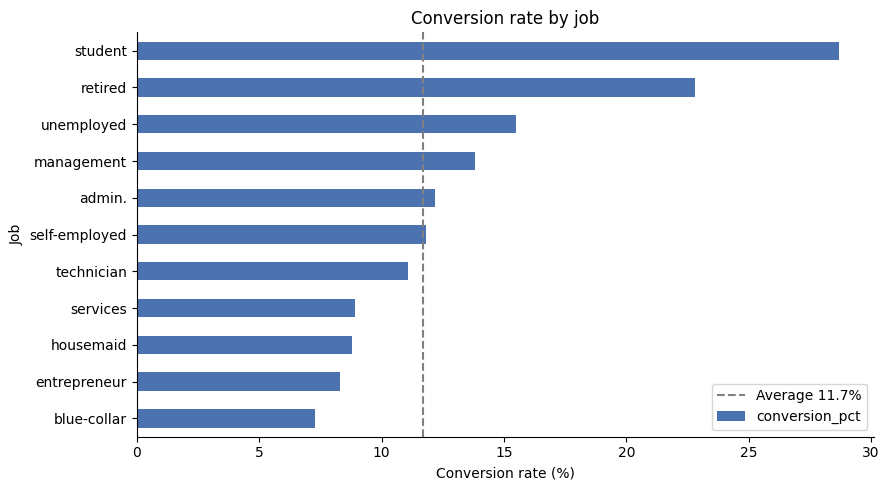

In [20]:
def bar_chart(series, title, xlabel, filename, horizontal=False):
    fig, ax = plt.subplots()
    if horizontal:
        series.sort_values().plot.barh(ax=ax, color="#4C72B0")
        ax.axvline(overall_rate * 100, color="gray", linestyle="--", label=f"Average {overall_rate:.1%}")
        ax.set_xlabel("Conversion rate (%)")
        ax.set_ylabel(xlabel)
    else:
        series.plot.bar(ax=ax, color="#4C72B0", rot=0)
        ax.axhline(overall_rate * 100, color="gray", linestyle="--", label=f"Average {overall_rate:.1%}")
        ax.set_ylabel("Conversion rate (%)")
        ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(IMG_DIR / filename, dpi=150)
    plt.show()

bar_chart(job_rates.set_index("job")["conversion_pct"], "Conversion rate by job", "Job",
          "conversion_by_job.png", horizontal=True)

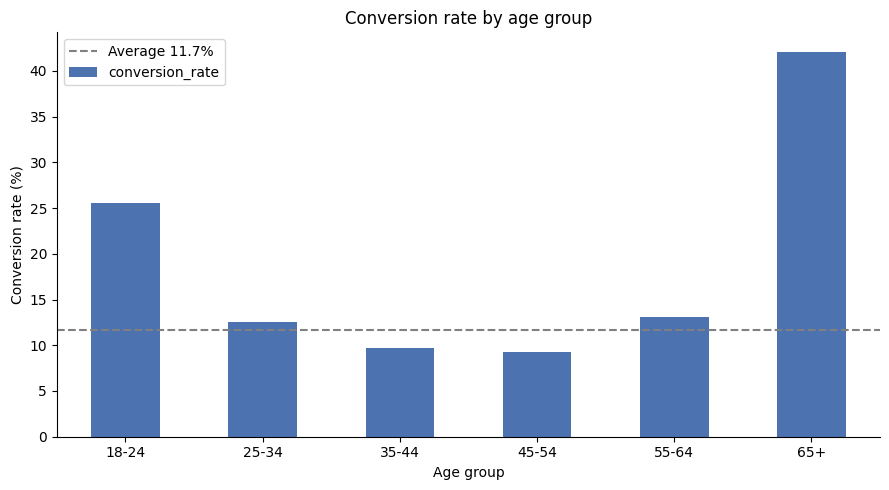

In [21]:
bar_chart(age_rates["conversion_rate"], "Conversion rate by age group", "Age group",
          "conversion_by_age.png")

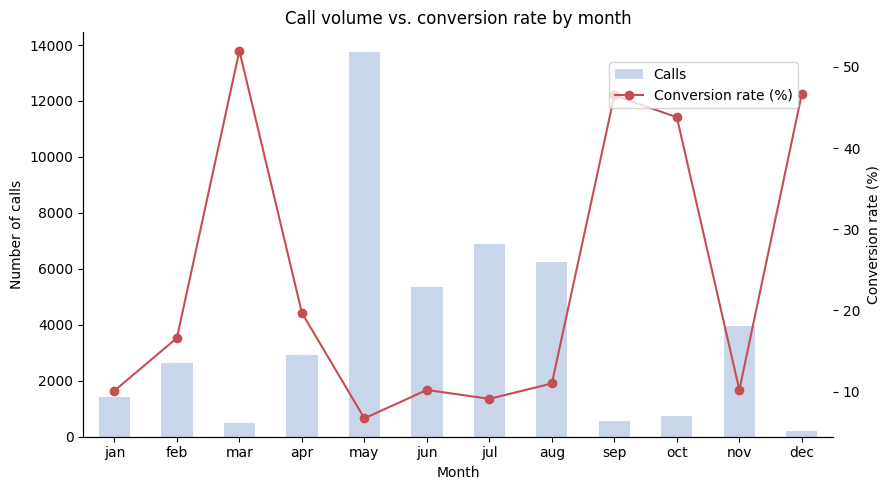

In [22]:
# Month chart: call volume vs conversion rate, to show whether busy months are the effective ones
fig, ax1 = plt.subplots()
month_rates["calls"].plot.bar(ax=ax1, color="#C9D6EA", rot=0, label="Calls")
ax1.set_ylabel("Number of calls")
ax1.set_xlabel("Month")
ax2 = ax1.twinx()
ax2.plot(range(len(month_rates)), month_rates["conversion_rate"], color="#C44E52", marker="o",
         label="Conversion rate (%)")
ax2.set_ylabel("Conversion rate (%)")
ax1.set_title("Call volume vs. conversion rate by month")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
fig.tight_layout()
fig.savefig(IMG_DIR / "volume_vs_conversion_by_month.png", dpi=150)
plt.show()

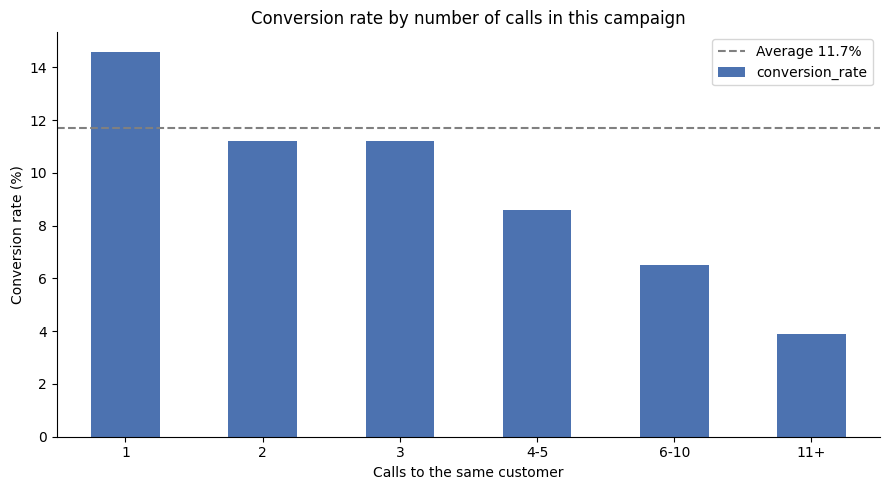

In [23]:
bar_chart(call_rates["conversion_rate"], "Conversion rate by number of calls in this campaign",
          "Calls to the same customer", "conversion_by_call_count.png")

## 8. Key numbers for the summary

In [24]:
prev_success = prev_outcome.set_index("previous_outcome").loc["success", "conversion_pct"]
best_job = job_rates.iloc[0]
top_month = month_rates["conversion_rate"].idxmax()
busiest_month = month_rates["calls"].idxmax()
one_call = call_rates.loc["1", "conversion_rate"]
many_calls = call_rates.loc["6-10", "conversion_rate"]

print(f"Overall conversion rate: {overall_rate:.1%}")
print(f"Customers whose previous campaign succeeded: {prev_success}% "
      f"({prev_success / (overall_rate * 100):.1f}x the average)")
print(f"Best job group: {best_job['job']} at {best_job['conversion_pct']}%")
print(f"Busiest month: {busiest_month} at {month_rates.loc[busiest_month, 'conversion_rate']}% conversion")
print(f"Best month: {top_month} at {month_rates.loc[top_month, 'conversion_rate']}% conversion")
print(f"1 call: {one_call}% vs. 6-10 calls: {many_calls}%")

Overall conversion rate: 11.7%
Customers whose previous campaign succeeded: 64.7% (5.5x the average)
Best job group: student at 28.7%
Busiest month: may at 6.7% conversion
Best month: mar at 52.0% conversion
1 call: 14.6% vs. 6-10 calls: 6.5%


## 9. Recommendations

1. **Prioritize warm leads.** Customers who subscribed in a previous campaign converted at 64.7%, 5.5x the 11.7% average, yet they were only 1,511 of 45,211 calls (3%). Call them first.
2. **Target the strongest segments.** Students (28.7%), retirees (22.8%) and customers aged 65+ (42.1%) or 18-24 (25.6%) convert well above average; blue-collar customers convert at 7.3%.
3. **Rethink timing.** May had 30% of all calls but the lowest conversion rate (6.7%). March, September, October and December converted above 40%, but each had fewer than 800 calls, so test moving some volume before committing.
4. **Cap repeat calls.** Conversion drops from 14.6% after one call to 6.5% at 6-10 calls and 3.9% at 11+. A cap of about 3 calls frees time for new leads.

**Limitations:** the data comes from one bank in 2008-2010, so results may not transfer directly to other markets; some segments (65+, the high-converting months) are small; conversion rates show association, not cause.